# Transfer entropy lineal-gaussiana entre TPM y EPM

**Pregunta que responde este cuaderno.** ¿El pasado de una serie TPM reduce la incertidumbre sobre el siguiente valor de una serie EPM, **más allá de lo que ya dice el propio pasado del EPM**? Esta es la definición de transfer entropy (TE) de Schreiber (2000).

**Qué se hace, en tres pasos:**
1. **Cuánto pasado del EPM se condiciona (k).** Se elige con el criterio BIC sobre un modelo autorregresivo de cada sensor EPM.
2. **El valor de la TE.** Se estima con el estimador lineal-gaussiano: se comparan dos regresiones, una que predice el EPM solo con su pasado y otra que además usa el TPM. Para procesos gaussianos esta cantidad es exactamente la TE (Barnett, Barrett y Seth, 2009).
3. **Si el valor es distinguible del azar.** Se usan dos tipos de sustitutos de la serie fuente (TPM): **barajado aleatorio**, que es una nula permisiva, y **desplazamiento circular**, que es una nula exigente.

**Qué NO responde.**
- No mide dependencia puramente no lineal. Esa parte la cubre CCM, en otro cuaderno.
- No demuestra que el TPM sirva para imputar la brecha de 681 días. La TE mide información predictiva **a un paso (6 h)**; la utilidad para imputar se valida con brechas artificiales.
- No es una prueba de causalidad física. Es dependencia estadística dirigida.

**Datos:** `Data_limpia_completa/EPM_completo.csv` y `Data_limpia_completa/TPM_completo.csv`, tramo previo a la brecha, rejilla de 6 h.

## Referencias

Las marcadas con **[verificar]** no se han contrastado contra el PDF original. Antes de citarlas en la tesis hay que confirmar volumen, páginas y contenido.

- **Schreiber, T. (2000).** Measuring information transfer. *Phys. Rev. Lett.* 85(2), 461–464. Define la TE.
- **Barnett, L., Barrett, A. B. y Seth, A. K. (2009).** Granger causality and transfer entropy are equivalent for Gaussian variables. *Phys. Rev. Lett.* 103, 238701. **[verificar]** Justifica el estimador lineal-gaussiano.
- **Geweke, J. (1982).** Measurement of linear dependence and feedback between multiple time series. *J. Amer. Statist. Assoc.* 77(378), 304–313. **[verificar]** Medida $\ln(\sigma^2_r/\sigma^2_c)$.
- **Granger, C. W. J. (1969).** Investigating causal relations by econometric models and cross-spectral methods. *Econometrica* 37(3), 424–438. **[verificar]**
- **Schwarz, G. (1978).** Estimating the dimension of a model. *Ann. Statist.* 6(2), 461–464. **[verificar]** Criterio BIC.
- **Theiler, J., Eubank, S., Longtin, A., Galdrikian, B. y Farmer, J. D. (1992).** Testing for nonlinearity in time series: the method of surrogate data. *Physica D* 58, 77–94. Revisado en la carpeta `Referencias a subrogate` (preprint LA-UR-91-3343). La sec. 2.2.1 describe el barajado.
- **Scheinkman, J. A. y LeBaron, B. (1989).** Nonlinear dynamics and stock returns. *J. Business* 62, 311–337. **[verificar]** Origen del barajado según Theiler et al. (1992), sec. 2.2.1.
- **Kugiumtzis, D. (2013).** Partial transfer entropy on rank vectors. arXiv:1303.6454 (revisado en la carpeta `Referencias a subrogate`). Revista **[verificar]**. La sec. 3.4 usa sustitutos por desplazamiento circular para la TE; la nota al pie 2 da el p mínimo ≈ 1/(M+1).
- **Quian Quiroga, R., Kraskov, A., Kreuz, T. y Grassberger, P. (2002).** Performance of different synchronization measures in real data. *Phys. Rev. E* 65, 041903. **[verificar]** Fuente que Kugiumtzis cita para el desplazamiento circular.
- **Phipson, B. y Smyth, G. K. (2010).** Permutation p-values should never be zero. *Stat. Appl. Genet. Mol. Biol.* 9(1), art. 39. **[verificar]** Fórmula $p=(1+b)/(M+1)$.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- Constantes ----------------
ARCHIVO_EPM = 'Data_limpia_completa/EPM_completo.csv'
ARCHIVO_TPM = 'Data_limpia_completa/TPM_completo.csv'
BRECHA_INICIO = pd.Timestamp('2023-06-20')   # se usa solo el tramo previo a la brecha
PASO_H = 6                                   # rejilla de 6 horas

LAGS = np.arange(1, 29)        # rezagos tau del TPM: 1 a 28 pasos = 6 h a 7 dias
K_MAX = 24                     # mayor k (pasado del EPM) que se le ofrece al BIC = 6 dias
N_SUR = 199                    # sustitutos por prueba -> p minimo = 1/200 = 0.005
MIN_SHIFT = 2 * LAGS.max()     # desplazamiento circular minimo (ver seccion 4)
ALFA = 0.05
SEMILLA = 2026                 # semilla fija: resultados reproducibles

ARCHIVO_RESULTADOS = 'te_gaussiana_resultados.csv'
IMG_DIR = Path('img')
IMG_DIR.mkdir(exist_ok=True)

series_tpm = ['POT(1)', 'POT(2)', 'POT(3)', 'POT(4)', 'POT(5)', 'POT(6)', 'POT(7)',
              'Tilt(1)', 'Tilt(2)', 'Tilt(3)', 'Tilt(4)', 'Tilt(5)', 'Tilt(6)', 'Tilt(7)']
series_epm = ['Sensor 1 (5m)', 'Sensor 2 (10m)', 'Sensor 3 (5m)', 'Sensor 4 (10m)']

## 1. Carga de datos y rejilla de 6 h

Es la misma construcción de `tpm y ccm (revision rigurosa).ipynb`:
- Se toma el tramo previo a la brecha.
- Se promedia cada serie en ventanas de 6 h (`resample('6h').mean()`). Antes de la brecha el EPM se lee a las 01, 07, 13 y 19 h y el TPM a las 00, 06, 12 y 18 h; ambas lecturas caen en la misma ventana.
- **No se rellenan huecos** (sin `ffill`/`bfill`). Las ventanas vacías quedan como NaN y las regresiones descartan esas filas.

Se analizan dos versiones:
- **Niveles:** las series tal cual.
- **Diferencias:** el cambio entre pasos consecutivos, $\Delta y_t = y_t - y_{t-1}$. Quita la tendencia, que puede inflar la dependencia aparente entre dos series que solo comparten deriva.

In [2]:
epm_raw = pd.read_csv(ARCHIVO_EPM, parse_dates=['date'])
tpm_raw = pd.read_csv(ARCHIVO_TPM, parse_dates=['date'])

epm_r = (epm_raw[epm_raw['date'] < BRECHA_INICIO]
         .set_index('date').sort_index().resample(f'{PASO_H}h').mean())
tpm_r = (tpm_raw[tpm_raw['date'] < BRECHA_INICIO]
         .drop(columns=['freq']).set_index('date').sort_index().resample(f'{PASO_H}h').mean())

df_niveles = epm_r.join(tpm_r, how='inner')          # SIN ffill/bfill
df_diferencias = df_niveles.diff().iloc[1:]

VERSIONES = {'niveles': df_niveles, 'diferencias': df_diferencias}

print(f'Ventana: {df_niveles.index.min()} a {df_niveles.index.max()}')
print(f'Posiciones de 6 h: {len(df_niveles)}  |  filas con algun NaN: {df_niveles.isna().any(axis=1).sum()}')

Ventana: 2022-11-09 18:00:00 a 2023-06-19 18:00:00
Posiciones de 6 h: 889  |  filas con algun NaN: 4


## 2. El estimador: TE lineal-gaussiana

**Idea.** Se ajustan dos regresiones para predecir el siguiente valor del EPM, $Y_{t+1}$:

- **Modelo restringido** (solo el pasado del EPM):
$$Y_{t+1} = a_0 + a_1 Y_t + \dots + a_k Y_{t-k+1} + \varepsilon^{(r)}_t$$
- **Modelo completo** (agrega el TPM de hace $\tau$ pasos):
$$Y_{t+1} = b_0 + b_1 Y_t + \dots + b_k Y_{t-k+1} + c\,X_{t-\tau} + \varepsilon^{(c)}_t$$

Si el TPM no aporta nada nuevo, los dos modelos se equivocan igual. Si aporta, el modelo completo se equivoca menos. La TE mide esa reducción del error:

$$TE_{X\to Y}(\tau) = \tfrac{1}{2}\log_2\frac{\sigma^2_{r}}{\sigma^2_{c}} \quad \text{[bits]}$$

donde $\sigma^2_r$ y $\sigma^2_c$ son las varianzas de los residuos de cada modelo. $\ln(\sigma^2_r/\sigma^2_c)$ es la medida de Geweke (1982), y para variables gaussianas la mitad de esa cantidad es exactamente la TE de Schreiber (Barnett et al., 2009). Aquí se usa $\log_2$ para expresarla en bits.

**Cómo leer el tamaño.** Despejando, el porcentaje en que el TPM reduce la varianza del error de predicción del EPM es:
$$\text{reducción} = 100\,\big(1 - \sigma^2_c/\sigma^2_r\big) = 100\,\big(1-2^{-2\,TE}\big)\ \%$$
Este es el número interpretable: "conocer el TPM reduce en un X % el error de predicción del EPM a 6 h".

**Detalles:**
- Del TPM se usa un solo valor, $X_{t-\tau}$ (orden $l=1$). El retardo se explora variando $\tau$ de 1 a 28.
- Los dos modelos se ajustan **sobre las mismas filas**: se descarta cualquier fila con NaN en $Y$, en sus rezagos o en $X$. Así la comparación es justa.
- Para cada par se reporta el máximo sobre los 28 rezagos (`te_max`) y el rezago donde ocurre (`tau_optimo`). $\tau^*$ **no** se interpreta como un retardo físico, porque sale de maximizar sobre ruido.

In [3]:
def matriz_rezagos(y, k, t_idx):
    """Columnas [y_t, y_{t-1}, ..., y_{t-k+1}] para cada t en t_idx."""
    return np.column_stack([y[t_idx - j] for j in range(k)])


def te_gauss(x, y, k, tau):
    """
    TE lineal-gaussiana X -> Y al rezago tau, condicionando en k valores pasados de Y.
    Devuelve (te_bits, n_filas_usadas).
    """
    t = np.arange(max(k - 1, tau), len(y) - 1)
    Y = y[t + 1]
    Ly = matriz_rezagos(y, k, t)
    Xs = x[t - tau]
    ok = ~np.isnan(Y) & ~np.isnan(Ly).any(axis=1) & ~np.isnan(Xs)   # mismas filas en ambos modelos
    Y, Ly, Xs = Y[ok], Ly[ok], Xs[ok]
    n = len(Y)

    Xr = np.column_stack([np.ones(n), Ly])        # modelo restringido
    Xc = np.column_stack([Xr, Xs])                # modelo completo
    br, *_ = np.linalg.lstsq(Xr, Y, rcond=None)
    bc, *_ = np.linalg.lstsq(Xc, Y, rcond=None)
    s2r = np.mean((Y - Xr @ br) ** 2)
    s2c = np.mean((Y - Xc @ bc) ** 2)
    return 0.5 * np.log2(s2r / s2c), n


def te_max_lags(x, y, k, lags=LAGS):
    """TE en cada rezago y su maximo."""
    vals = np.array([te_gauss(x, y, k, int(l))[0] for l in lags])
    i = int(np.argmax(vals))
    return {'te_max': float(vals[i]), 'tau_optimo': int(lags[i]), 'te_por_lag': vals}


def reduccion_pct(te_bits):
    """Porcentaje de reduccion de la varianza del error de prediccion."""
    return 100 * (1 - 2 ** (-2 * np.asarray(te_bits)))

## 3. Cuánto pasado del EPM condicionar: k por BIC

Si se condiciona en muy poco pasado del EPM (por ejemplo $k=1$), el TPM puede parecer informativo solo porque "recuerda" algo que el propio EPM ya sabía y no se incluyó. Eso inflaría la TE.

**Criterio.** Para cada sensor EPM, y por separado en niveles y diferencias, se ajustan modelos autorregresivos de orden $k = 1,\dots,$ `K_MAX`. Se elige el $k$ que minimiza

$$\text{BIC}(k) = n\ln\hat\sigma^2_k + (k+1)\ln n$$

(Schwarz, 1978). El primer término premia el ajuste y el segundo castiga cada parámetro añadido. Ese mismo $k$ se usa en todos los pares de ese sensor. Es coherente con el estimador: el modelo restringido de la sección 2 **es** ese modelo autorregresivo.

Todos los órdenes se comparan sobre **las mismas filas** (las que admiten `K_MAX` rezagos), porque el BIC solo compara modelos ajustados a los mismos datos.

In [4]:
def orden_bic(y, k_max=K_MAX):
    t = np.arange(k_max - 1, len(y) - 1)
    Y = y[t + 1]
    L = matriz_rezagos(y, k_max, t)
    ok = ~np.isnan(Y) & ~np.isnan(L).any(axis=1)
    Y, L = Y[ok], L[ok]
    n = len(Y)
    bics = []
    for k in range(1, k_max + 1):
        X = np.column_stack([np.ones(n), L[:, :k]])
        b, *_ = np.linalg.lstsq(X, Y, rcond=None)
        bics.append(n * np.log(np.mean((Y - X @ b) ** 2)) + (k + 1) * np.log(n))
    return int(np.argmin(bics)) + 1


K_POR_SENSOR = {v: {s: orden_bic(d[s].values) for s in series_epm} for v, d in VERSIONES.items()}

tabla_k = pd.DataFrame(K_POR_SENSOR)
tabla_k['niveles (horas)'] = tabla_k['niveles'] * PASO_H
tabla_k['diferencias (horas)'] = tabla_k['diferencias'] * PASO_H
tabla_k

,niveles,diferencias,niveles (horas),diferencias (horas)
Sensor 1 (5m),8,7,48,42
Sensor 2 (10m),9,8,54,48
Sensor 3 (5m),7,6,42,36
Sensor 4 (10m),8,7,48,42


## 4. ¿El valor es distinguible del azar? Dos tipos de sustitutos

Aunque el TPM no aporte nada, la TE estimada sale algo mayor que cero: con datos finitos, el modelo completo siempre ajusta un poco mejor por azar. Para saber si un valor es "de verdad" se compara con la TE que se obtiene cuando la relación con el EPM se destruye a propósito. Esa es la idea del método de datos sustitutos (Theiler et al., 1992). **Solo se altera la fuente (TPM); el EPM queda intacto.**

| Sustituto | Qué hace | Qué conserva del TPM | Hipótesis nula | Fuente |
|---|---|---|---|---|
| **Barajado** | Permuta al azar el orden temporal del TPM | Solo sus valores (su histograma) | "El TPM es ruido i.i.d. sin relación con el EPM" | Theiler et al. (1992), sec. 2.2.1, que lo atribuyen a Scheinkman y LeBaron (1989) |
| **Desplazamiento circular** | Rota el TPM un número aleatorio $w$ de pasos | Sus valores **y** su autocorrelación (su forma) | "El TPM tiene su propia dinámica, pero no está alineado en el tiempo con el EPM" | Kugiumtzis (2013), sec. 3.4, que cita a Quian Quiroga et al. (2002) |

**Cómo se leen juntos.** Las dos nulas conservan cosas distintas del TPM, y ninguna es siempre más permisiva que la otra con este estimador (ver la sección 7):
- El barajado destruye toda la estructura temporal del TPM, incluido cualquier ciclo diario.
- El desplazamiento conserva la autocorrelación y los ciclos del TPM. Como la nula toma el máximo sobre 28 rezagos, un ciclo de período ≤ 28 pasos se vuelve a alinear con el EPM en algún rezago, sea cual sea el desplazamiento. Por eso **una dependencia que solo consista en compartir un ciclo diario no supera la prueba de desplazamiento**.
- Un par que pasa las dos pruebas aporta información que no se explica ni por azar ni por la estructura propia del TPM (sus ciclos incluidos).

**Desplazamiento mínimo** `MIN_SHIFT` $=2\times 28 = 56$ pasos (14 días). Desplazar $w$ pasos y luego mirar el rezago $\tau$ equivale a mirar el TPM original en el rezago $\tau+w$. Si $w \le 28$, el sustituto reproduciría rezagos que la propia prueba explora y la nula quedaría contaminada con la relación real. Se exige $w \in [56,\ n-56]$, con margen del doble. **Esta es una decisión de diseño propia, no tomada de los artículos.**

**Máximo sobre rezagos también en la nula.** El dato real se resume con el máximo sobre 28 rezagos, y elegir el mejor de 28 infla el valor aunque no haya relación. Para comparar en igualdad de condiciones, a **cada sustituto** también se le calcula el máximo sobre los 28 rezagos.

**p-valor.** Con $b$ = número de sustitutos cuya TE máxima es $\ge$ la del dato:
$$p = \frac{1+b}{M+1}$$
(Phipson y Smyth, 2010). Con $M=199$ el p mínimo posible es $0.005$ (Kugiumtzis, 2013, nota al pie 2). Un $p=0.005$ significa "el dato superó a los 199 sustitutos".

**Comparaciones múltiples.** No se aplica una corrección formal. Se reporta cuántos de los 56 pares tienen $p<0.05$ y se compara con lo esperable por azar: $56\times0.05\approx2.8$. Por eso **ningún par individual se declara "significativo"**; la lectura es del conjunto.

In [5]:
def nula_barajado(x, y, k, rng, n_sur=N_SUR):
    return np.array([te_max_lags(rng.permutation(x), y, k)['te_max'] for _ in range(n_sur)])


def nula_desplazamiento(x, y, k, rng, n_sur=N_SUR, min_shift=MIN_SHIFT):
    n = len(x)
    return np.array([te_max_lags(np.roll(x, rng.integers(min_shift, n - min_shift + 1)), y, k)['te_max']
                     for _ in range(n_sur)])


def p_valor(nula, observado):
    return (1 + int(np.sum(nula >= observado))) / (len(nula) + 1)

## 5. Batería: 14 TPM × 4 EPM × 2 versiones

Para cada par y cada versión se calcula:
- `te_max` y `tau_optimo` (TE en bits y el rezago donde ocurre),
- `reduccion_pct` (porcentaje de reducción del error de predicción),
- `n` (filas usadas),
- `p_barajado` y `p_desplazamiento`,
- `te_efectiva`: `te_max` menos la media de la nula del desplazamiento. Descuenta el sesgo positivo del estimador.

Tarda unos **7 minutos**. Los resultados se guardan en `te_gaussiana_resultados.csv`. Si ese archivo existe, se carga en vez de recalcular; para recalcular, borrarlo.

In [6]:
if Path(ARCHIVO_RESULTADOS).exists():
    resultados = pd.read_csv(ARCHIVO_RESULTADOS)
    print(f'Cargado desde cache: {ARCHIVO_RESULTADOS} ({len(resultados)} filas)')
else:
    rng = np.random.default_rng(SEMILLA)
    filas = []
    t0 = time.time()
    for version, d in VERSIONES.items():
        for epm_col in series_epm:
            k = K_POR_SENSOR[version][epm_col]
            y = d[epm_col].values
            for tpm_col in series_tpm:
                x = d[tpm_col].values
                obs = te_max_lags(x, y, k)
                _, n_usadas = te_gauss(x, y, k, obs['tau_optimo'])
                nula_b = nula_barajado(x, y, k, rng)
                nula_d = nula_desplazamiento(x, y, k, rng)
                filas.append({
                    'version': version, 'TPM': tpm_col, 'EPM': epm_col, 'k': k,
                    'tau_optimo': obs['tau_optimo'],
                    'tau_optimo_horas': obs['tau_optimo'] * PASO_H,
                    'te_max': obs['te_max'],
                    'reduccion_pct': float(reduccion_pct(obs['te_max'])),
                    'te_efectiva': obs['te_max'] - float(np.mean(nula_d)),
                    'n': n_usadas,
                    'p_barajado': p_valor(nula_b, obs['te_max']),
                    'p_desplazamiento': p_valor(nula_d, obs['te_max']),
                })
        print(f'{version}: listo ({(time.time() - t0) / 60:.1f} min acumulados)')
    resultados = pd.DataFrame(filas)
    resultados.to_csv(ARCHIVO_RESULTADOS, index=False)
    print(f'Guardado: {ARCHIVO_RESULTADOS}')

resultados.head()

Cargado desde cache: te_gaussiana_resultados.csv (112 filas)


,version,TPM,EPM,k,tau_optimo,tau_optimo_horas,te_max,reduccion_pct,te_efectiva,n,p_barajado,p_desplazamiento
0,niveles,POT(1),Sensor 1 (5m),8,21,126,0.001928,0.266881,0.001014,831,0.985,0.010
1,niveles,POT(2),Sensor 1 (5m),8,25,150,0.001095,0.151630,-0.000097,827,1.000,0.415
2,niveles,POT(3),Sensor 1 (5m),8,22,132,0.002698,0.373276,0.001730,830,0.905,0.015
3,niveles,POT(4),Sensor 1 (5m),8,1,6,0.014266,1.958291,0.011586,845,0.005,0.005
4,niveles,POT(5),Sensor 1 (5m),8,22,132,0.001518,0.210239,-0.000322,830,1.000,0.590


## 6. Resumen: ¿cómo va la cosa?

In [7]:
esperado_azar = len(series_tpm) * len(series_epm) * ALFA

resumen = []
for version, g in resultados.groupby('version', sort=False):
    pb = g['p_barajado'] < ALFA
    pd_ = g['p_desplazamiento'] < ALFA
    resumen.append({
        'version': version,
        'p<0.05 barajado': int(pb.sum()),
        'p<0.05 desplazamiento': int(pd_.sum()),
        'pasan ambos': int((pb & pd_).sum()),
        'esperado por azar': round(esperado_azar, 1),
        'reduccion % mediana': round(g['reduccion_pct'].median(), 2),
        'reduccion % maxima': round(g['reduccion_pct'].max(), 2),
    })
pd.DataFrame(resumen).set_index('version')

,p<0.05 barajado,p<0.05 desplazamiento,pasan ambos,esperado por azar,reduccion % mediana,reduccion % maxima
version,,,,,,
niveles,17,18,14,2.8,0.85,7.94
diferencias,25,1,1,2.8,1.20,4.82


In [8]:
# Pares que pasan ambas pruebas, ordenados por reduccion del error
cols = ['version', 'TPM', 'EPM', 'k', 'tau_optimo_horas', 'te_max', 'reduccion_pct',
        'p_barajado', 'p_desplazamiento']
ambos = resultados[(resultados['p_barajado'] < ALFA) & (resultados['p_desplazamiento'] < ALFA)]
ambos[cols].sort_values(['version', 'reduccion_pct'], ascending=[True, False]).reset_index(drop=True)

,version,TPM,EPM,k,tau_optimo_horas,te_max,reduccion_pct,p_barajado,p_desplazamiento
0,diferencias,POT(4),Sensor 1 (5m),7,6,0.034837,4.714723,0.005,0.005
1,niveles,Tilt(4),Sensor 1 (5m),8,6,0.059714,7.944691,0.005,0.005
2,niveles,POT(6),Sensor 1 (5m),8,6,0.037103,5.013496,0.005,0.005
3,niveles,Tilt(5),Sensor 1 (5m),8,6,0.036965,4.995395,0.005,0.005
4,niveles,Tilt(4),Sensor 3 (5m),7,78,0.031504,4.273327,0.005,0.005
5,niveles,Tilt(4),Sensor 4 (10m),8,18,0.021946,2.996556,0.005,0.005
6,niveles,Tilt(3),Sensor 1 (5m),8,6,0.020627,2.818981,0.005,0.005
7,niveles,Tilt(5),Sensor 4 (10m),8,18,0.019800,2.707525,0.005,0.005
8,niveles,Tilt(5),Sensor 3 (5m),7,78,0.019316,2.642169,0.005,0.005
9,niveles,Tilt(3),Sensor 3 (5m),7,150,0.016860,2.310208,0.005,0.020


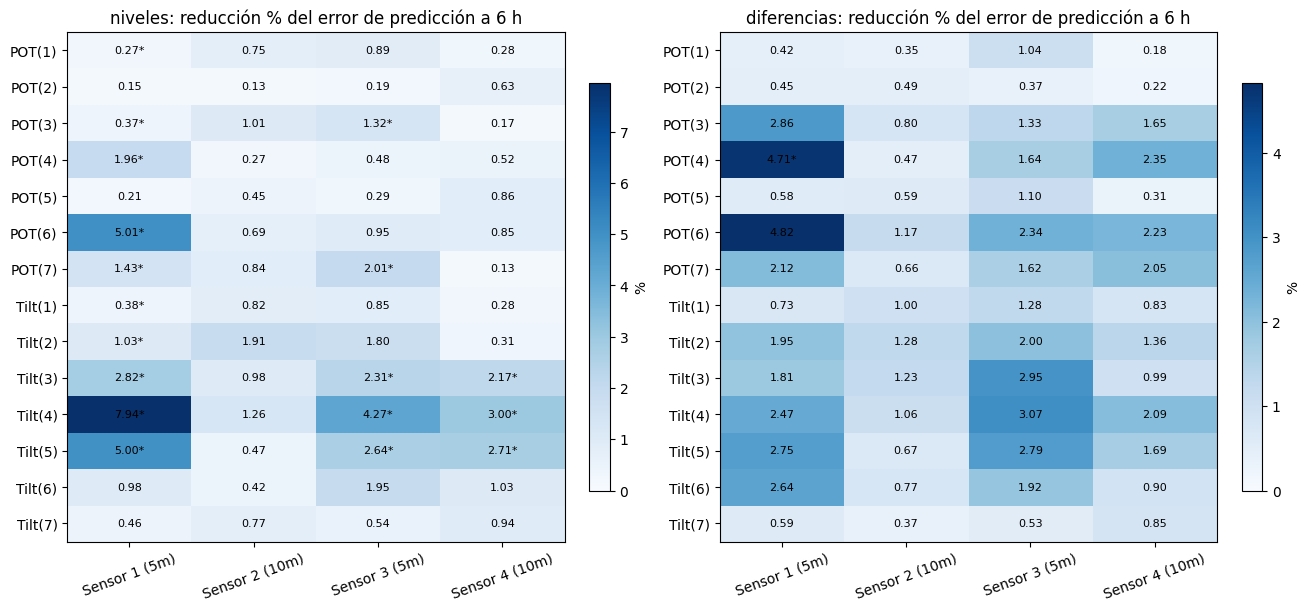

In [9]:
# Heatmap: reduccion % del error de prediccion. Marca: * = pasa el desplazamiento (p<0.05)
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, version in zip(axes, VERSIONES):
    g = resultados[resultados['version'] == version]
    mat = g.pivot(index='TPM', columns='EPM', values='reduccion_pct').loc[series_tpm, series_epm]
    pmat = g.pivot(index='TPM', columns='EPM', values='p_desplazamiento').loc[series_tpm, series_epm]
    im = ax.imshow(mat.values, cmap='Blues', aspect='auto', vmin=0)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            marca = '*' if pmat.values[i, j] < ALFA else ''
            ax.text(j, i, f'{mat.values[i, j]:.2f}{marca}', ha='center', va='center', fontsize=8)
    ax.set_xticks(range(len(series_epm)), series_epm, rotation=20)
    ax.set_yticks(range(len(series_tpm)), series_tpm)
    ax.set_title(f'{version}: reducción % del error de predicción a 6 h')
    fig.colorbar(im, ax=ax, shrink=0.8, label='%')
fig.savefig(IMG_DIR / 'te_gaussiana_heatmap.png', dpi=150)
plt.show()

## 7. Cómo leer los resultados y limitaciones

**Lectura:**
- **`reduccion_pct`** responde "¿grande o pequeño?": cuánto baja el error de predicción del EPM a 6 h al agregar el TPM, después de usar el propio pasado del EPM.
- **Los p-valores** responden "¿distinguible del azar?". Se leen en conjunto: cuántos pares tienen $p<0.05$ frente a los ≈ 2.8 esperables por azar.
- **Niveles frente a diferencias:** si la dependencia aparece en niveles y desaparece en diferencias, es compatible con una tendencia compartida y no con información a corto plazo.

**Limitaciones declaradas:**
1. **Solo dependencia lineal.** Una relación puramente no lineal puede dar TE ≈ 0. Esto se complementa con CCM. Es la misma clase de dependencia que puede aprovechar un modelo de procesos gaussianos, cuya media posterior es lineal en los datos.
2. **Horizonte de 6 h.** Información predictiva a corto plazo no es lo mismo que utilidad para imputar una brecha de 681 días.
3. **Desplazamiento circular:** también rompe la relación del TPM con el pasado del EPM, no solo el acople directo (Kugiumtzis, 2013, sec. 3.4, lo llama "a point of inconsistency"). Con series de tendencia fuerte, el desplazamiento crea un salto en el punto de unión.
4. **Sin corrección formal por comparaciones múltiples.** No se declara significativo ningún par individual.
5. **Decisiones de diseño propias:** rejilla de 6 h, rezagos 1 a 28, `MIN_SHIFT` = 56, orden $l=1$ para el TPM, `K_MAX` = 24.

**Hallazgo de la primera corrida (2026-10-22): ciclo de 24 h.** Las series en diferencias tienen autocorrelación positiva en los rezagos 4 y 8 (24 h y 48 h). Por ejemplo, en el rezago 4: Sensor 1 0.33, Tilt(4) 0.46, POT(4) 0.25. Hay una componente diaria que comparten ambos sistemas; su causa no está confirmada (la temperatura es solo una hipótesis). Esto explica la diferencia entre las dos pruebas en diferencias: el barajado destruye el ciclo y rechaza en muchos pares, mientras que el desplazamiento conserva el ciclo y casi no rechaza. En diferencias, la dependencia de corto plazo que detecta el barajado es compatible con un ciclo diario compartido, no con información adicional del TPM. En niveles ocurre lo contrario: la nula del barajado es **mayor** que la del desplazamiento, porque un ruido i.i.d. evaluado en 28 rezagos ofrece 28 oportunidades casi independientes de ajustar por azar, mientras que una serie suave ofrece muchas menos.

## 8. Gráfica por par: TE vs rezago y prueba de sustitutos

Para un par elegido se dibujan dos paneles.

**Izquierda: TE en cada rezago, en las dos direcciones.**
- Azul: $T_{TPM\to EPM}(\tau)$, la dirección de interés.
- Naranja: $T_{EPM\to TPM}(\tau)$, la dirección de control. En esta dirección el objetivo es el TPM, así que su $k$ se elige con BIC sobre la serie TPM.
- Banda gris: el 95 % central de la TE de los sustitutos por desplazamiento **en cada rezago**. Un punto azul fuera de la banda es un rezago donde el dato supera a lo esperable sin alineación.
- Línea roja: el **umbral para el máximo**, el percentil 95 de los máximos de los sustitutos por desplazamiento. Es con este umbral que se compara `te_max`, porque el dato también es un máximo sobre los 28 rezagos.

**Derecha: las dos nulas del máximo.** Histogramas del máximo sobre rezagos para los sustitutos por barajado y por desplazamiento, con el valor observado. El p-valor mínimo posible es $1/(M+1)=0.005$; nunca se reporta $p=0$.

Las nulas se recalculan aquí con la misma semilla base, así que los p-valores pueden diferir ligeramente de los de la batería, que se generaron en otra secuencia aleatoria.

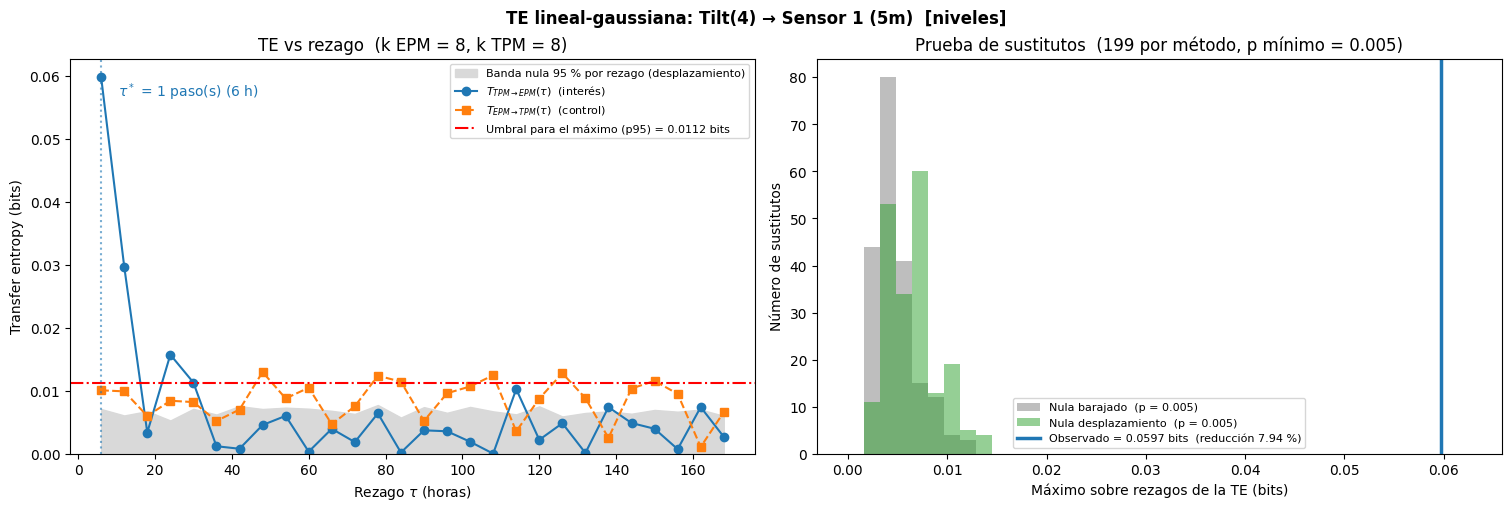

In [10]:
def bandas_desplazamiento(x, y, k, rng, n_sur=N_SUR, min_shift=MIN_SHIFT):
    """TE por rezago de cada sustituto desplazado -> matriz (n_sur, len(LAGS))."""
    n = len(x)
    return np.array([te_max_lags(np.roll(x, rng.integers(min_shift, n - min_shift + 1)), y, k)['te_por_lag']
                     for _ in range(n_sur)])


def graficar_par(tpm_col, epm_col, version='niveles', guardar=True):
    d = VERSIONES[version]
    x, y = d[tpm_col].values, d[epm_col].values
    k_epm = K_POR_SENSOR[version][epm_col]
    k_tpm = orden_bic(x)                      # k para la direccion de control (objetivo = TPM)
    rng = np.random.default_rng(SEMILLA)

    fwd = te_max_lags(x, y, k_epm)
    bwd = te_max_lags(y, x, k_tpm)
    mat_d = bandas_desplazamiento(x, y, k_epm, rng)
    nula_d = mat_d.max(axis=1)
    nula_b = nula_barajado(x, y, k_epm, rng)
    p_d, p_b = p_valor(nula_d, fwd['te_max']), p_valor(nula_b, fwd['te_max'])
    umbral = np.percentile(nula_d, 95)
    horas = LAGS * PASO_H

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

    ax1.fill_between(horas, np.percentile(mat_d, 2.5, axis=0), np.percentile(mat_d, 97.5, axis=0),
                     color='0.85', label='Banda nula 95 % por rezago (desplazamiento)')
    ax1.plot(horas, fwd['te_por_lag'], 'o-', color='tab:blue', label=r'$T_{TPM\to EPM}(\tau)$  (interés)')
    ax1.plot(horas, bwd['te_por_lag'], 's--', color='tab:orange', label=r'$T_{EPM\to TPM}(\tau)$  (control)')
    ax1.axhline(umbral, color='red', ls='-.', label=f'Umbral para el máximo (p95) = {umbral:.4f} bits')
    ax1.axvline(fwd['tau_optimo'] * PASO_H, color='tab:blue', ls=':', alpha=0.6)
    ax1.annotate(rf'$\tau^*$ = {fwd["tau_optimo"]} paso(s) ({fwd["tau_optimo"] * PASO_H} h)',
                 xy=(fwd['tau_optimo'] * PASO_H, fwd['te_max']), xytext=(12, -14),
                 textcoords='offset points', color='tab:blue')
    ax1.set_xlabel(r'Rezago $\tau$ (horas)')
    ax1.set_ylabel('Transfer entropy (bits)')
    ax1.set_title(f'TE vs rezago  (k EPM = {k_epm}, k TPM = {k_tpm})')
    ax1.set_ylim(bottom=0)
    ax1.legend(fontsize=8)

    bins = np.linspace(0, max(nula_b.max(), nula_d.max(), fwd['te_max']) * 1.05, 40)
    ax2.hist(nula_b, bins=bins, alpha=0.5, color='tab:gray', label=f'Nula barajado  (p = {p_b:.3f})')
    ax2.hist(nula_d, bins=bins, alpha=0.5, color='tab:green', label=f'Nula desplazamiento  (p = {p_d:.3f})')
    ax2.axvline(fwd['te_max'], color='tab:blue', lw=2.5,
                label=f'Observado = {fwd["te_max"]:.4f} bits  (reducción {reduccion_pct(fwd["te_max"]):.2f} %)')
    ax2.set_xlabel('Máximo sobre rezagos de la TE (bits)')
    ax2.set_ylabel('Número de sustitutos')
    ax2.set_title(f'Prueba de sustitutos  ({N_SUR} por método, p mínimo = {1 / (N_SUR + 1):.3f})')
    ax2.legend(fontsize=8)

    fig.suptitle(f'TE lineal-gaussiana: {tpm_col} → {epm_col}  [{version}]', fontweight='bold')
    if guardar:
        nombre = f'te_gauss_{version}_{tpm_col}_{epm_col}'.replace(' ', '_').replace('(', '').replace(')', '')
        fig.savefig(IMG_DIR / f'{nombre}.png', dpi=150)
    plt.show()


graficar_par('Tilt(4)', 'Sensor 1 (5m)', 'niveles')

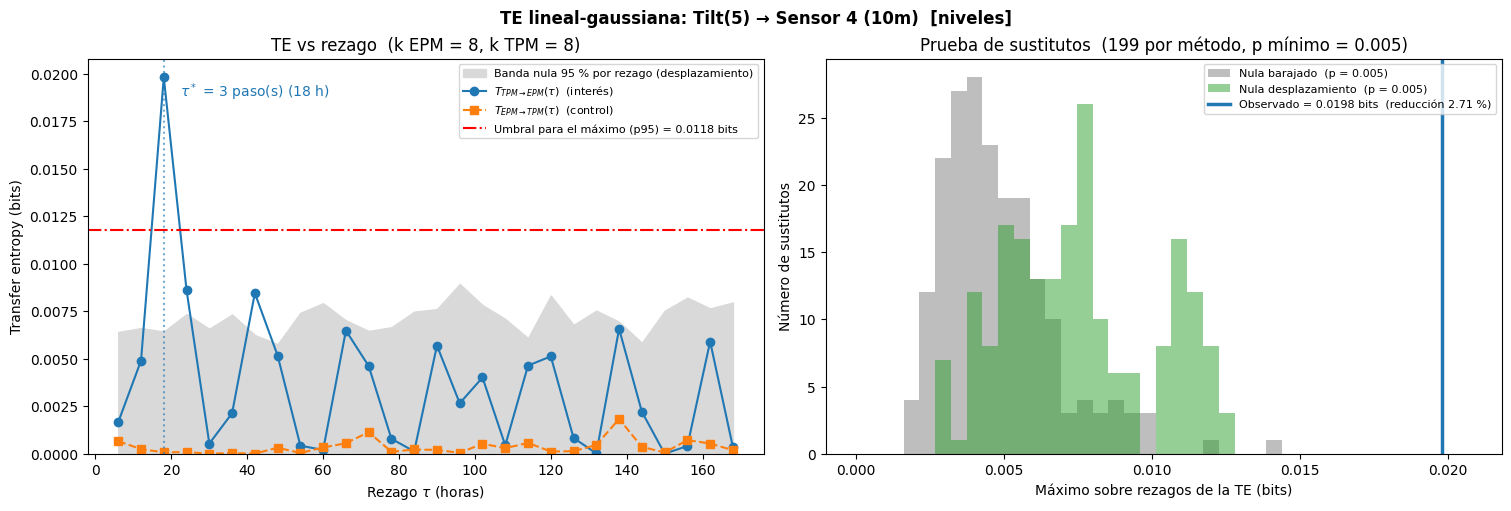

In [11]:
graficar_par('Tilt(5)', 'Sensor 4 (10m)', 'niveles')

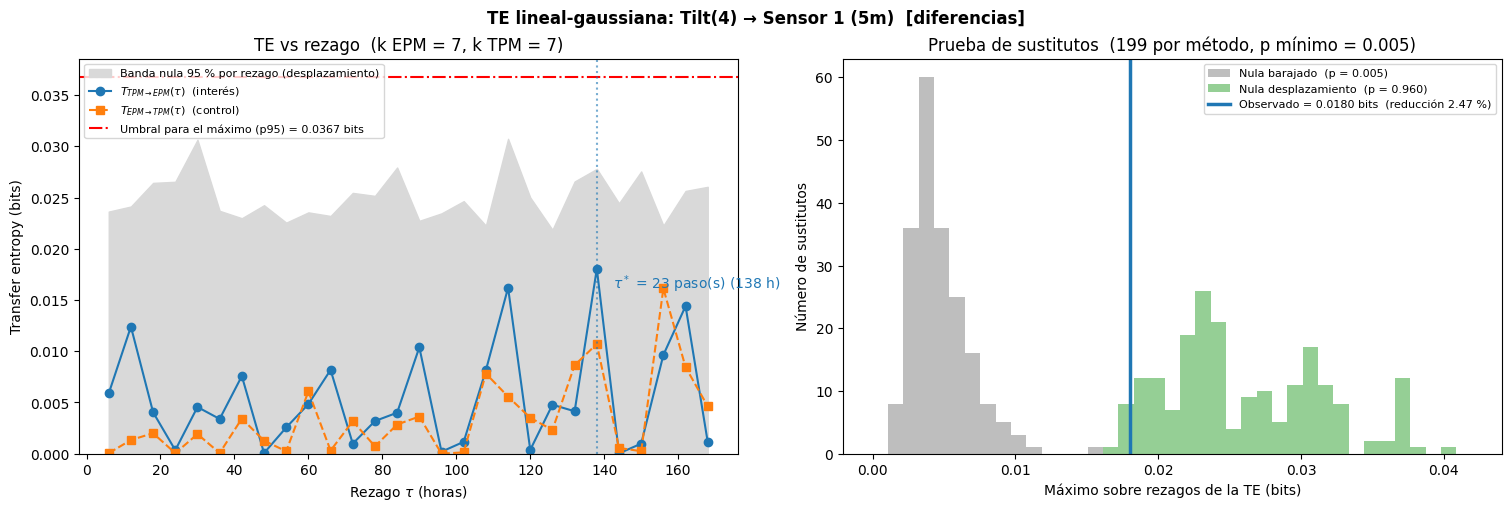

In [12]:
graficar_par('Tilt(4)', 'Sensor 1 (5m)', 'diferencias')